In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn xgboost imbalanced-learn

In [ ]:
# ===============================
# 📊 Import Libraries
# ===============================
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import StackingClassifier

from google.colab import files
import pandas as pd


In [ ]:
# Upload file
uploaded = files.upload()

# Load Excel
df = pd.read_csv("Ecommerce_customer_churn.csv")

# ===============================
# 📂 Load Dataset
# ===============================
print("Before cleaning:", df.shape)

In [ ]:
# ===============================
# 🧹 Handling Missing Values
# ===============================
# Fill numeric with mean, categorical with mode
for col in df.columns:
    if df[col].dtype == "object":
        df[col] = df[col].fillna(df[col].mode()[0])
    else:
        df[col] = df[col].fillna(df[col].mean())

print("After cleaning:", df.isnull().sum().sum(), "missing values")

After cleaning: 0 missing values


In [ ]:
# ===============================
# 🔄 Encode categorical variables
# ===============================
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])

In [ ]:
# ===============================
# ✨ Feature Engineering
# ===============================
if "CashbackAmount" in df.columns and "OrderCount" in df.columns:
    df["OrderCashbackRatio"] = df["CashbackAmount"] / (df["OrderCount"] + 1)

if "SatisfactionScore" in df.columns and "Tenure" in df.columns:
    df["LoyaltyScore"] = df["SatisfactionScore"] * df["Tenure"]

if "HourSpendOnApp" in df.columns and "NumberOfDeviceRegistered" in df.columns:
    df["Engagement"] = df["HourSpendOnApp"] * df["NumberOfDeviceRegistered"]

if "Complain" in df.columns:
    df["Complain"] = df["Complain"].apply(lambda x: 1 if x in [1, "Yes", "yes"] else 0)


In [ ]:
# ===============================
# 🎯 Features and Target
# ===============================
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Balance dataset with SMOTE
smote = SMOTE()
X, y = smote.fit_resample(X, y)

# ===============================
# 📏 Feature Scaling
# ===============================
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
# ===============================
# 🤖 Machine Learning Models
# ===============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(probability=True),
    "KNN": KNeighborsClassifier(),
    "XGBoost": XGBClassifier(eval_metric='logloss')
}

results = {}

In [ ]:
# ===============================
# 🔄 Cross Validation (StratifiedKFold)
# ===============================
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print("="*50)
    print(f"🔹 Evaluating {name} ...")

    cv_scores = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
    avg_score = cv_scores.mean()

    results[name] = avg_score
    print(f"Cross-Validation Accuracy: {cv_scores}")
    print(f"Mean Accuracy: {avg_score:.4f}")

🔹 Evaluating Logistic Regression ...
Cross-Validation Accuracy: [0.78804058 0.80832888 0.81793914 0.81687133 0.80715812]
Mean Accuracy: 0.8077
🔹 Evaluating Decision Tree ...
Cross-Validation Accuracy: [0.91564335 0.9252536  0.92845702 0.92792312 0.93215812]
Mean Accuracy: 0.9259
🔹 Evaluating Random Forest ...
Cross-Validation Accuracy: [0.96636412 0.95835558 0.96102509 0.97010144 0.97596154]
Mean Accuracy: 0.9664
🔹 Evaluating SVM ...
Cross-Validation Accuracy: [0.92044848 0.91190603 0.92258409 0.92205019 0.93215812]
Mean Accuracy: 0.9218
🔹 Evaluating KNN ...
Cross-Validation Accuracy: [0.868126   0.88307528 0.87346503 0.87666845 0.89155983]
Mean Accuracy: 0.8786
🔹 Evaluating XGBoost ...
Cross-Validation Accuracy: [0.9807795  0.97650828 0.9802456  0.98611853 0.98397436]
Mean Accuracy: 0.9815


In [ ]:
# Build Stacking Ensemble
stack_model = StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(n_estimators=200, random_state=42)),
        ("xgb", XGBClassifier(eval_metric="logloss")),
        ("svc", SVC(probability=True))
    ],
    final_estimator=LogisticRegression(max_iter=1000)
)

cv_scores = cross_val_score(stack_model, X, y, cv=skf, scoring="accuracy")
print("\nStacking CV Accuracy:", cv_scores.mean())


Stacking CV Accuracy: 0.9291975828347958


In [ ]:
# Train final model
best_model = stack_model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("\nFinal Model Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))


Final Model Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       937
           1       0.99      0.99      0.99       936

    accuracy                           0.99      1873
   macro avg       0.99      0.99      0.99      1873
weighted avg       0.99      0.99      0.99      1873

Confusion Matrix:
 [[923  14]
 [ 11 925]]


In [ ]:
# ===============================
# 🎯 Features and Target (numeric for ML)
# ===============================
X = df.drop("Churn", axis=1)
y = df["Churn"]   # stays numeric for training

# ===============================
# 📊 Copy for Visualization
# ===============================
df_plot = df.copy()
df_plot['Churn'] = df_plot['Churn'].map({1: "Not Interested", 0: "Interested"})

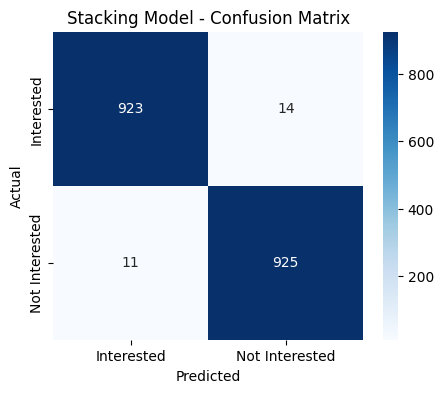

In [ ]:
# ===============================
# 🔲 Confusion Matrix Heatmap
# ===============================
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Interested","Not Interested"], yticklabels=["Interested","Not Interested"])
plt.title("Stacking Model - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


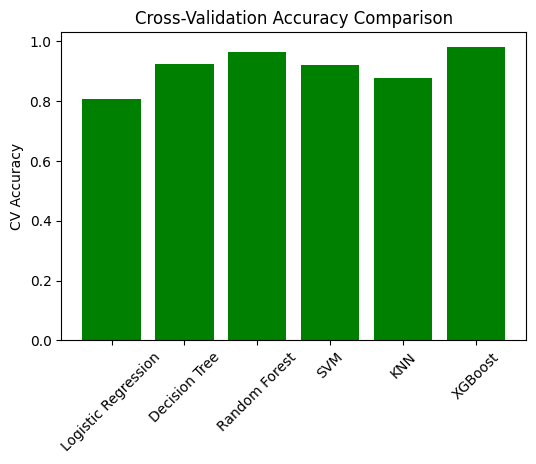

In [ ]:

# ===============================
# 📊 Model Comparison
# ===============================
plt.figure(figsize=(6,4))
plt.bar(results.keys(), results.values(), color='green')
plt.xticks(rotation=45)
plt.ylabel("CV Accuracy")
plt.title("Cross-Validation Accuracy Comparison")
plt.show()

In [ ]:
# Set style
sns.set(style="whitegrid")


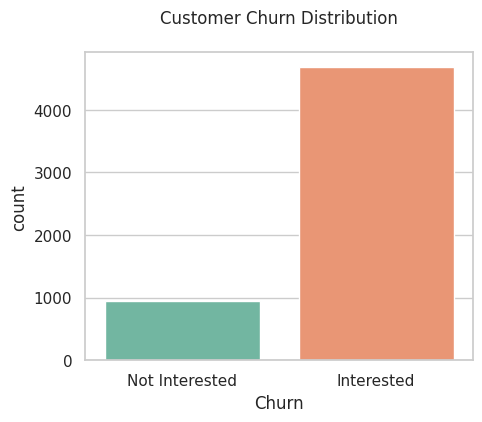

In [ ]:
# 1️⃣ Churn Count Plot
plt.figure(figsize=(5,4))
sns.countplot(x="Churn", data=df_plot, hue="Churn", palette="Set2", legend=False)
plt.title("Customer Churn Distribution\n")
plt.show()

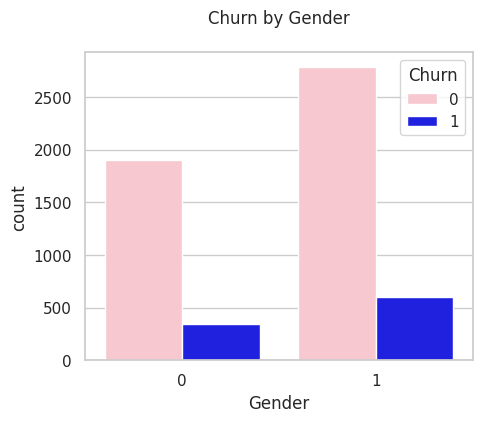

In [ ]:
# 2️⃣ Churn by Gender
plt.figure(figsize=(5,4))
sns.countplot(x="Gender", hue="Churn", data=df, palette=["pink","blue"],dodge=True)
plt.title("Churn by Gender\n")
plt.show()

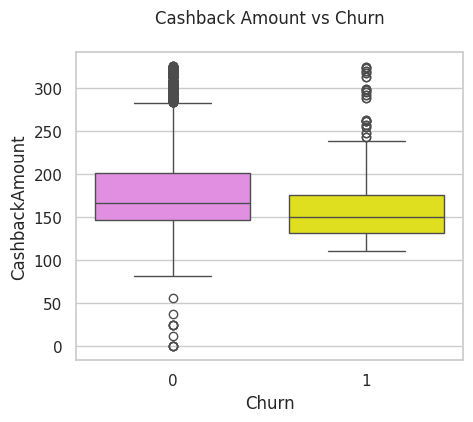

In [ ]:
# 3️⃣ Total Cashback vs Churn (Boxplot)
plt.figure(figsize=(5,4))
sns.boxplot(x="Churn", y="CashbackAmount", data=df, hue="Churn", palette=["violet", "yellow"], legend=False)
plt.title("Cashback Amount vs Churn\n")
plt.show()

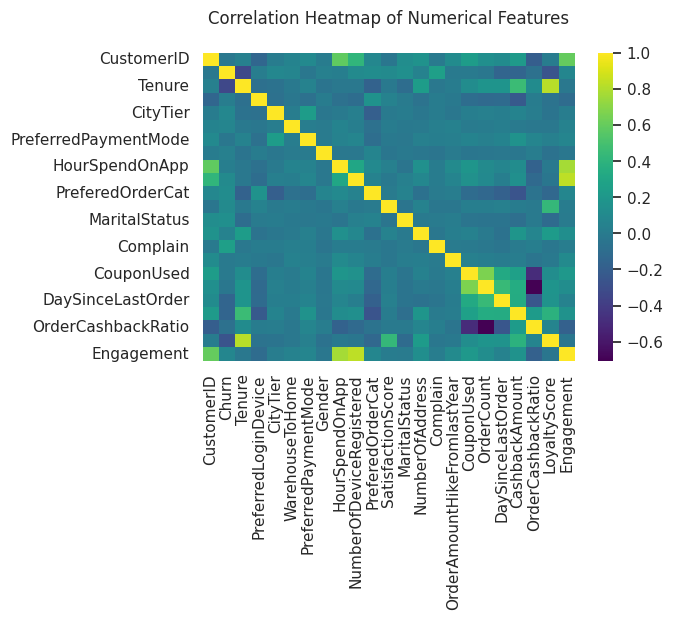

In [ ]:
# 4️⃣ Correlation Heatmap (numeric only)
plt.figure(figsize=(6,4))
sns.heatmap(df.corr(), annot=False, cmap="viridis")
plt.title("Correlation Heatmap of Numerical Features\n")
plt.show()

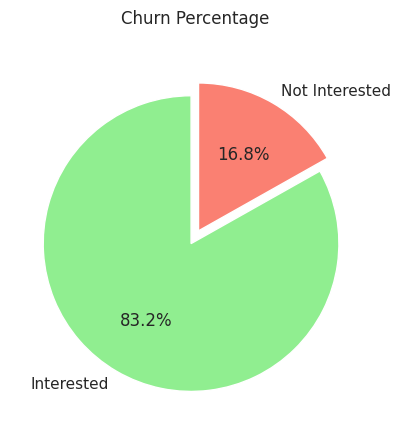

In [ ]:
# 5️⃣ Pie Chart for Churn
df['Churn'] = df['Churn'].map({1: "Not Interested", 0: "Interested"})
df['Churn'].value_counts().plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=["lightgreen","salmon"],
    explode=(0.05, 0.05)
)
plt.ylabel("")
plt.title("Churn Percentage\n")
plt.show()

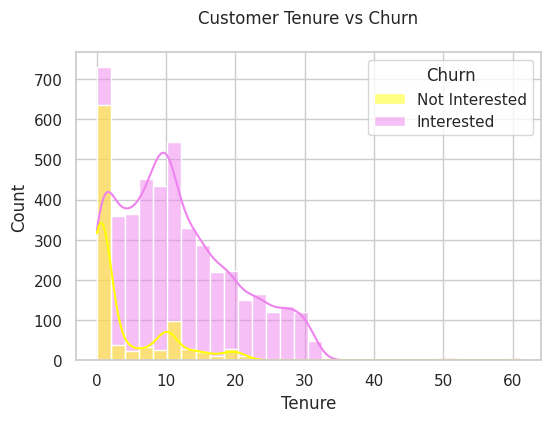

In [ ]:
# 6️⃣ Tenure vs Churn (Histogram)
plt.figure(figsize=(6,4))
sns.histplot(data=df, x="Tenure", hue="Churn", bins=30, kde=True, palette=["yellow","violet"])
plt.title("Customer Tenure vs Churn\n")
plt.show()

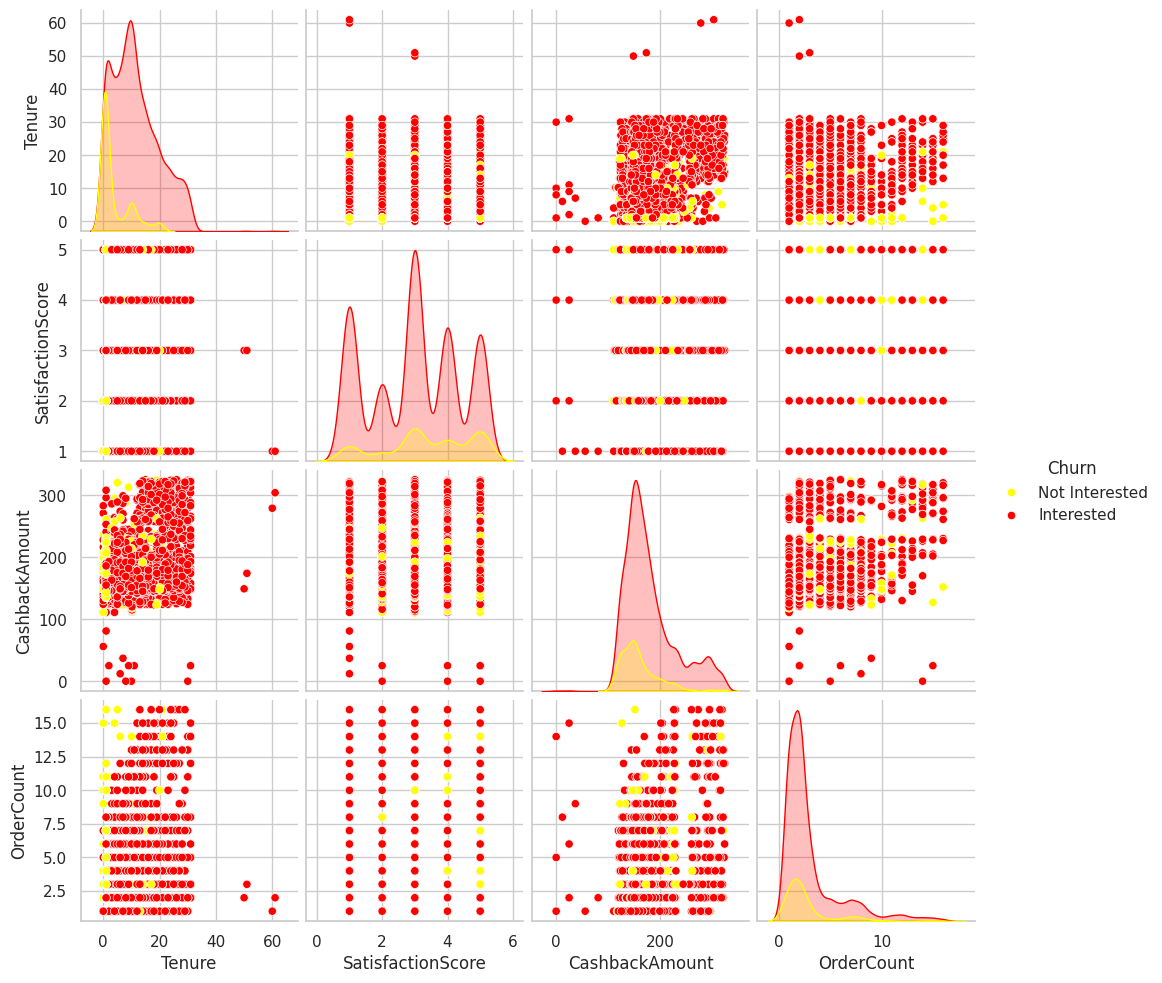

In [ ]:
# 7️⃣ Pairplot (Selected Features)
sns.pairplot(
    df[['Tenure','SatisfactionScore','CashbackAmount','OrderCount','Churn']],
    hue="Churn",
    palette=["yellow","red"]
)
plt.show()

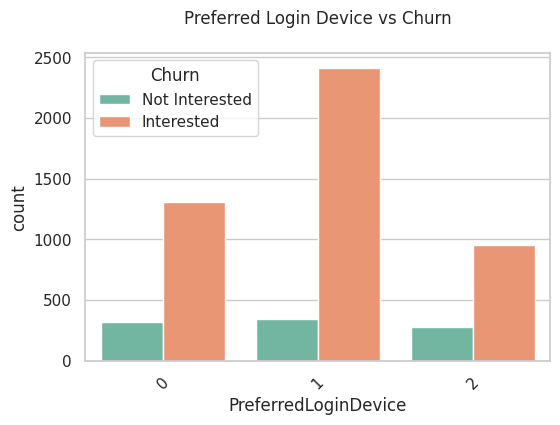

In [ ]:
# ===============================
# 📊 Categorical Feature Analysis
# ===============================

# 8️⃣ Preferred Login Device vs Churn
plt.figure(figsize=(6,4))
sns.countplot(x="PreferredLoginDevice", hue="Churn", data=df, palette="Set2")
plt.title("Preferred Login Device vs Churn\n")
plt.xticks(rotation=45)
plt.show()


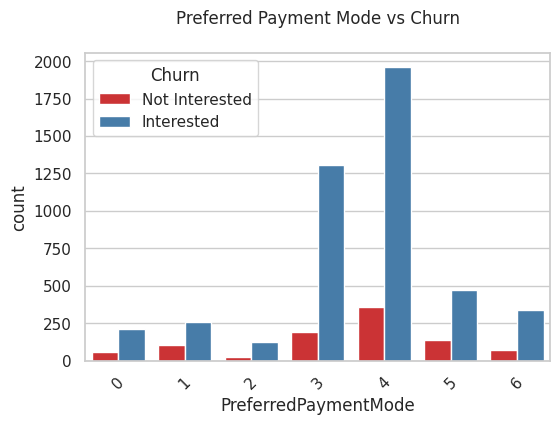

In [ ]:
# 9️⃣ Preferred Payment Mode vs Churn
plt.figure(figsize=(6,4))
sns.countplot(x="PreferredPaymentMode", hue="Churn", data=df, palette="Set1")
plt.title("Preferred Payment Mode vs Churn\n")
plt.xticks(rotation=45)
plt.show()

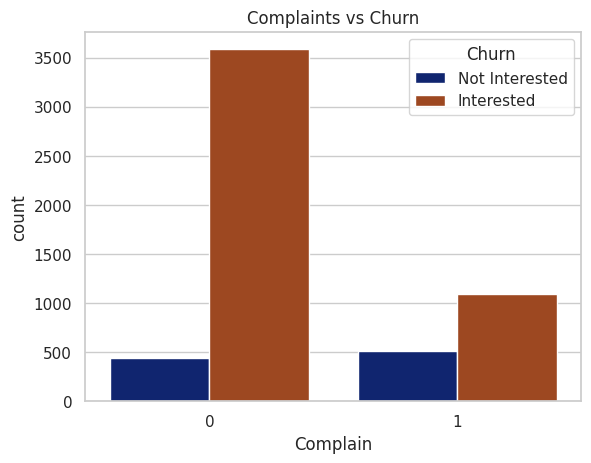

In [ ]:
# 🔟 Complaints vs Churn
sns.countplot(x="Complain", hue="Churn", data=df, palette="dark")
plt.title("Complaints vs Churn")
plt.show()

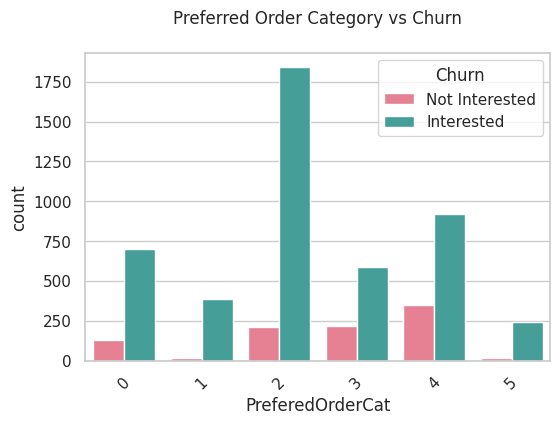

In [ ]:
# 1️⃣1️⃣ Preferred Order Category vs Churn
plt.figure(figsize=(6,4))
sns.countplot(x="PreferedOrderCat", hue="Churn", data=df, palette="husl")
plt.title("Preferred Order Category vs Churn\n")
plt.xticks(rotation=45)
plt.show()

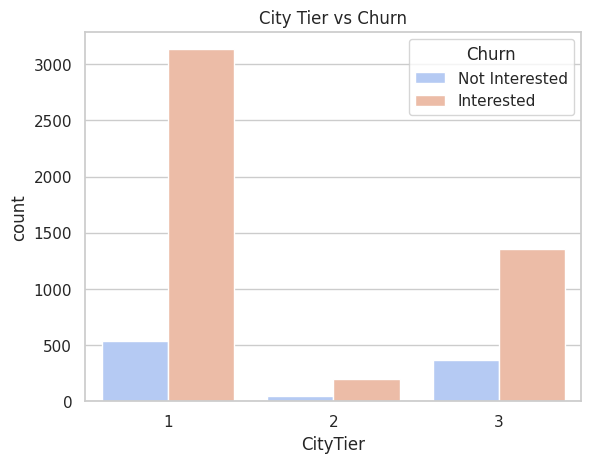

In [ ]:
# 1️⃣2️⃣City Tier vs Churn
sns.countplot(x="CityTier", hue="Churn", data=df, palette="coolwarm")
plt.title("City Tier vs Churn")
plt.show()

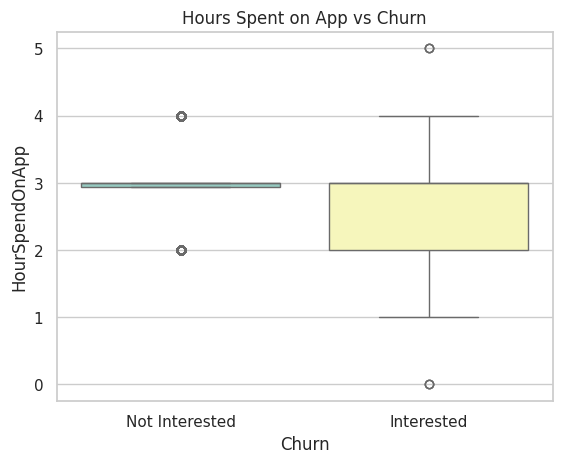

In [ ]:
# 1️⃣3️⃣Hours Spent on App vs Churn
sns.boxplot(x="Churn", y="HourSpendOnApp", data=df, hue="Churn", palette="Set3", legend=False)
plt.title("Hours Spent on App vs Churn")
plt.show()